# Lab 01 · 토크나이저(BPE)와 어텐션을 밑바닥부터

**이 실습이 다루는 자료** ([필독 목록](../READING_LIST.md) · [실습 가이드](../PRACTICE.md))

| 절 | 직접 확인할 것 | 관련 자료 |
|---|---|---|
| 1 | 가장 자주 붙어 나오는 쌍을 합치는 것만으로 토크나이저가 만들어진다 | Sennrich et al. (2015) *BPE*, Karpathy *Let's build the GPT Tokenizer* |
| 2 | 어텐션 식 한 줄을 NumPy로 구현하고 PyTorch와 대조 | Vaswani et al. (2017) *Attention Is All You Need* 3.2.1절 |
| 3 | $\sqrt{d_k}$ 로 나누는 이유 | 같은 논문 3.2.1절의 각주 설명 |
| 4 | 미래를 못 보게 하는 causal mask | GPT 계열 디코더 |
| 5 | 멀티헤드 = 같은 연산을 여러 부분공간에서 병렬로 | 같은 논문 3.2.2절 |
| 6 | 어텐션은 순서를 모른다 → 위치 인코딩 | 같은 논문 3.5절 |

**소요 시간**: 90분 · **패키지**: numpy, matplotlib, torch (1절 끝의 비교만 transformers 사용)  
먼저 [어텐션·Transformer 기초 문서](../../00_Foundations/06_attention-transformer.md)를 읽고 오면 좋습니다.

In [1]:
import numpy as np, matplotlib.pyplot as plt, torch, torch.nn as nn, torch.nn.functional as F
rng = np.random.default_rng(0)
plt.rcParams.update({"figure.figsize": (6, 3.5), "figure.dpi": 80})

## 1. BPE 토크나이저 만들기 (Sennrich et al., 2015)

모델은 글자가 아니라 **토큰 번호**를 봅니다. GPT 계열 토크나이저의 학습 절차는 놀랄 만큼 단순합니다.

1. 텍스트를 UTF-8 **바이트**(0~255)로 바꾼다. → 어떤 언어·이모지도 표현 가능, 초기 어휘 256개
2. 가장 자주 나오는 **인접한 쌍**을 찾아 새 토큰 번호 하나로 합친다.
3. 원하는 어휘 크기가 될 때까지 2를 반복한다.

✍️ **예측**: 한글 한 글자는 UTF-8에서 몇 바이트일까요? "데이터"는 합치기 전에 토큰 몇 개일까요?

In [2]:
text = """데이터 사이언티스트는 데이터를 모으고 데이터를 정리하고 데이터로 질문에 답한다.
좋은 데이터 사이언티스트는 모델보다 데이터를 먼저 본다. 모델을 학습하기 전에 데이터를 나누고,
학습 데이터와 검증 데이터와 테스트 데이터를 섞지 않는다. 논문을 읽을 때에도 데이터를 먼저 본다.
A data scientist reads the data before the model. The model learns from the training data,
and the test data tells us whether the model really learned or just memorized the training data.
논문을 읽고, 논문을 정리하고, 논문을 다시 구현해 보는 것이 가장 좋은 공부 방법이다."""

def pair_counts(ids):
    counts = {}
    for pair in zip(ids, ids[1:]): counts[pair] = counts.get(pair, 0) + 1
    return counts

def merge(ids, pair, new_id):
    out, i = [], 0
    while i < len(ids):
        if i < len(ids) - 1 and (ids[i], ids[i + 1]) == pair: out.append(new_id); i += 2
        else: out.append(ids[i]); i += 1
    return out

def train_bpe(text, num_merges):
    ids = list(text.encode("utf-8")); merges = {}
    for k in range(num_merges):
        counts = pair_counts(ids)
        if not counts: break                               # 더 합칠 쌍이 없다 (텍스트 전체가 한 토큰이 됨)
        pair = max(counts, key=counts.get)                 # 가장 자주 나오는 쌍
        ids = merge(ids, pair, 256 + k); merges[pair] = 256 + k
    vocab = {i: bytes([i]) for i in range(256)}
    for (a, b), new_id in merges.items(): vocab[new_id] = vocab[a] + vocab[b]
    return merges, vocab

def encode(text, merges):
    ids = list(text.encode("utf-8"))
    while len(ids) >= 2:
        counts = pair_counts(ids)
        pair = min(counts, key=lambda p: merges.get(p, float("inf")))   # 먼저 학습된 병합부터 적용
        if pair not in merges: break
        ids = merge(ids, pair, merges[pair])
    return ids

def decode(ids, vocab): return b"".join(vocab[i] for i in ids).decode("utf-8", errors="replace")

print('"데이터" 의 UTF-8 바이트 수:', len("데이터".encode("utf-8")))
merges, vocab = train_bpe(text, num_merges=120)
print("\n처음 학습된 병합 12개:")
for (a, b), new_id in list(merges.items())[:12]:
    print(f"  {new_id}: {vocab[a]!r} + {vocab[b]!r}  →  {vocab[new_id].decode('utf-8', errors='replace')!r}")

"데이터" 의 UTF-8 바이트 수: 9

처음 학습된 병합 12개:
  256: b' ' + b'\xeb'  →  ' �'
  257: b'\xec' + b'\x9d'  →  '�'
  258: b'\xec\x9d' + b'\xb4'  →  '이'
  259: b'\x8d' + b'\xb0'  →  '��'
  260: b'\x8d\xb0' + b'\xec\x9d\xb4'  →  '��이'
  261: b'\x8d\xb0\xec\x9d\xb4' + b'\xed'  →  '��이�'
  262: b'\x8d\xb0\xec\x9d\xb4\xed' + b'\x84'  →  '��이�'
  263: b'\x8d\xb0\xec\x9d\xb4\xed\x84' + b'\xb0'  →  '��이터'
  264: b' \xeb' + b'\x8d\xb0\xec\x9d\xb4\xed\x84\xb0'  →  ' 데이터'
  265: b' ' + b't'  →  ' t'
  266: b' ' + b'\xec'  →  ' �'
  267: b'h' + b'e'  →  'he'


In [3]:
n_bytes = len(text.encode("utf-8")); n_tokens = len(encode(text, merges))
print(f"학습 텍스트: {n_bytes} 바이트 → {n_tokens} 토큰 (압축률 {n_bytes / n_tokens:.2f}배)")
for s in ["데이터를 먼저 본다", "the training data", "처음 보는 문장 🙂"]:
    ids = encode(s, merges)
    print(f"{s!r:24} → {len(ids):2d} tokens  {[vocab[i].decode('utf-8', errors='replace') for i in ids]}")
    assert decode(ids, vocab) == s                               # 인코딩 → 디코딩이 원문과 같아야 한다

학습 텍스트: 690 바이트 → 210 토큰 (압축률 3.29배)
'데이터를 먼저 본다'             → 13 tokens  ['데이터', '�', '�', '�', ' �', '�', '�', '�', '�', '� �', '�', '�', '다']
'the training data'      →  9 tokens  ['t', 'he', ' t', 'r', 'a', 'in', 'in', 'g', ' data']
'처음 보는 문장 🙂'             → 19 tokens  ['�', '�', '�', '�', '�', ' �', '��', '는', ' �', '�', '�', '�', '�', '�', ' ', '�', '�', '�', '�']


- 한글 한 글자는 3바이트라서 처음에는 3토큰입니다. 병합이 진행되면 `이`, ` 데이터`(앞의 공백 포함)처럼 **자주 나오는 덩어리**가 한 토큰이 됩니다.
- 학습 텍스트에 없던 문장·이모지도 바이트로 쪼개져 **항상 인코딩됩니다**(OOV 없음). 대신 토큰 수가 늘어납니다.
- `�` 로 보이는 조각은 한글 한 글자의 일부 바이트만 담은 토큰입니다. 깨진 것이 아니라 아직 덜 합쳐진 것입니다.

실제 GPT-2 토크나이저(약 5만 개 어휘, 영어 중심 데이터로 학습)는 한국어를 어떻게 쪼갤까요?

In [4]:
try:
    from transformers import AutoTokenizer
    gpt2_tok = AutoTokenizer.from_pretrained("gpt2")
    for s in ["Data scientists read the data before the model.", "데이터 사이언티스트는 모델보다 데이터를 먼저 본다."]:
        print(f"{len(s):3d} 글자 → {len(gpt2_tok.encode(s)):3d} tokens | {s}")
except Exception as e:
    print("GPT-2 토크나이저를 내려받지 못해 건너뜁니다:", type(e).__name__)

 47 글자 →   9 tokens | Data scientists read the data before the model.
 28 글자 →  61 tokens | 데이터 사이언티스트는 모델보다 데이터를 먼저 본다.


같은 뜻의 문장인데 한국어가 훨씬 많은 토큰을 씁니다. 토크나이저가 어떤 데이터로 학습됐는지가 **비용(토큰 수)과 문맥 길이**에 직접 영향을 줍니다. 모델 카드에서 토크나이저와 학습 언어를 확인해야 하는 이유입니다.

## 2. 어텐션 한 줄을 구현하기 (Vaswani et al., 2017)

$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

- $QK^\top$: 모든 (질의, 키) 쌍의 내적 = 관련도 점수표 (n × n)
- softmax: 각 행을 합이 1인 가중치로
- $\cdot V$: 그 가중치로 값(value)들을 가중 평균

✍️ **예측**: 토큰이 5개이고 차원이 8이면 가중치 행렬과 출력의 shape은 각각 무엇일까요?

In [5]:
def softmax(x, axis=-1):
    x = x - x.max(axis=axis, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=axis, keepdims=True)

def attention(Q, K, V, mask=None):
    d_k = Q.shape[-1]
    scores = Q @ np.swapaxes(K, -1, -2) / np.sqrt(d_k)
    if mask is not None: scores = np.where(mask, scores, -1e9)       # 가릴 위치는 아주 작은 값 → softmax 후 0
    weights = softmax(scores)
    return weights @ V, weights

n, d = 5, 8
Q, K, V = rng.normal(size=(n, d)), rng.normal(size=(n, d)), rng.normal(size=(n, d))
out, w = attention(Q, K, V)
print("weights shape:", w.shape, "| 각 행의 합:", w.sum(axis=1).round(6), "| output shape:", out.shape)
ref = F.scaled_dot_product_attention(torch.tensor(Q), torch.tensor(K), torch.tensor(V)).numpy()
print("PyTorch 구현과의 최대 차이:", np.abs(out - ref).max())

weights shape: (5, 5) | 각 행의 합: [1. 1. 1. 1. 1.] | output shape: (5, 8)
PyTorch 구현과의 최대 차이: 2.220446049250313e-16


## 3. 왜 $\sqrt{d_k}$ 로 나누는가

논문의 설명: 차원이 크면 내적의 크기가 커져서 softmax가 기울기가 아주 작은 영역으로 밀려난다.  
평균 0, 분산 1인 성분을 가진 두 벡터의 내적은 분산이 $d_k$ 입니다. 즉 점수의 표준편차가 $\sqrt{d_k}$ 로 커집니다.

✍️ **예측**: 나누지 않으면 차원이 커질수록 어텐션 가중치는 고르게 퍼질까요, 한 곳에 몰릴까요?

In [6]:
print(" d_k | 점수의 표준편차 | 최대 가중치 평균 (스케일링 없음) | 최대 가중치 평균 (√d_k로 나눔)")
for d_k in [4, 64, 1024]:
    q = rng.normal(size=(2000, 1, d_k)); k = rng.normal(size=(2000, 16, d_k))          # 질의 1개, 키 16개 × 2000회
    raw = (q @ np.swapaxes(k, -1, -2))[:, 0, :]
    print(f"{d_k:5d} | {raw.std():15.2f} | {softmax(raw).max(axis=1).mean():32.3f} | {softmax(raw / np.sqrt(d_k)).max(axis=1).mean():.3f}")

 d_k | 점수의 표준편차 | 최대 가중치 평균 (스케일링 없음) | 최대 가중치 평균 (√d_k로 나눔)
    4 |            2.00 |                            0.430 | 0.235
   64 |            8.03 |                            0.849 | 0.248


 1024 |           31.99 |                            0.967 | 0.250


스케일링이 없으면 차원이 커질수록 가중치가 **한 토큰에 거의 1**로 몰립니다(one-hot에 가까움). 그러면 softmax의 기울기가 0에 가까워져 학습이 어렵습니다. $\sqrt{d_k}$ 로 나누면 차원과 무관하게 점수의 분산이 1로 유지됩니다.

## 4. Causal mask: 미래 토큰을 보지 못하게

GPT 같은 디코더는 "다음 토큰 예측"으로 학습하므로, 위치 $i$ 는 $i$ 이후를 보면 안 됩니다(정답을 미리 보는 셈). 점수 행렬의 **위쪽 삼각형**을 가립니다.

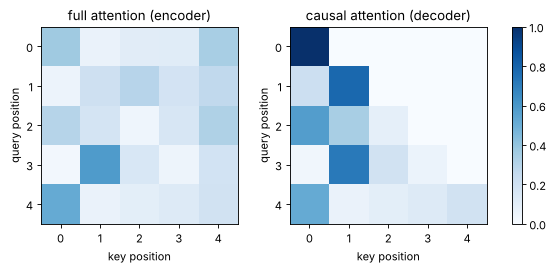

causal 가중치의 위쪽 삼각형 합 = 0.0


In [7]:
causal = np.tril(np.ones((n, n), dtype=bool))                      # 아래 삼각형만 True
out_c, w_c = attention(Q, K, V, mask=causal)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, m, title in zip(axes, [w, w_c], ["full attention (encoder)", "causal attention (decoder)"]):
    im = ax.imshow(m, cmap="Blues", vmin=0, vmax=1); ax.set_title(title); ax.set_xlabel("key position"); ax.set_ylabel("query position")
plt.colorbar(im, ax=axes, fraction=0.03); plt.show()
print("causal 가중치의 위쪽 삼각형 합 =", float(np.triu(w_c, 1).sum()))

## 5. 멀티헤드 어텐션

차원 $d$ 를 $h$ 개의 헤드로 나눠(각 $d/h$ 차원) 어텐션을 따로 계산한 뒤 이어 붙이고, 선형 변환을 한 번 더 합니다. 헤드마다 서로 다른 관계(문법, 지시 대상 등)를 볼 수 있게 하려는 설계입니다.

구현이 맞는지는 PyTorch `nn.MultiheadAttention` 의 가중치를 그대로 가져와 **같은 출력이 나오는지**로 확인합니다.

In [8]:
def multi_head_attention(x, Wq, Wk, Wv, Wo, n_heads, mask=None):
    n, d = x.shape; d_head = d // n_heads
    split = lambda t: t.reshape(n, n_heads, d_head).transpose(1, 0, 2)       # (heads, n, d_head)
    q, k, v = split(x @ Wq.T), split(x @ Wk.T), split(x @ Wv.T)
    out, weights = attention(q, k, v, mask)                                   # 헤드별로 독립 계산
    return out.transpose(1, 0, 2).reshape(n, d) @ Wo.T, weights               # 이어 붙이고 출력 변환

torch.manual_seed(0)
d, h = 16, 4
mha = nn.MultiheadAttention(d, h, bias=False, batch_first=True)
x = torch.randn(1, 6, d)
ref_out, ref_w = mha(x, x, x, need_weights=True, average_attn_weights=False)
Wq, Wk, Wv = mha.in_proj_weight.detach().numpy().reshape(3, d, d)
my_out, my_w = multi_head_attention(x[0].numpy(), Wq, Wk, Wv, mha.out_proj.weight.detach().numpy(), h)
print("출력 최대 차이:", np.abs(my_out - ref_out[0].detach().numpy()).max(), "| 가중치 shape (heads, n, n):", my_w.shape)

출력 최대 차이: 4.238358053409996e-08 | 가중치 shape (heads, n, n): (4, 6, 6)


## 6. 어텐션은 순서를 모른다 → 위치 인코딩

✍️ **예측**: 입력 토큰의 순서를 섞으면 self-attention의 출력은 어떻게 될까요?

순서를 섞은 입력의 출력 == 원래 출력을 같은 순서로 섞은 것 ? True


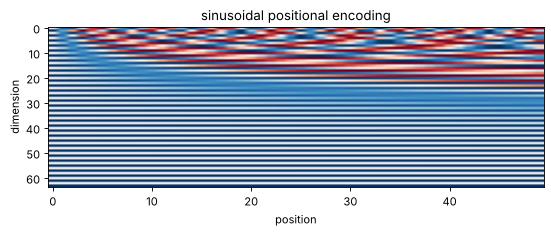

In [9]:
x_np = x[0].numpy(); perm = rng.permutation(len(x_np))
out_original, _ = multi_head_attention(x_np, Wq, Wk, Wv, mha.out_proj.weight.detach().numpy(), h)
out_shuffled, _ = multi_head_attention(x_np[perm], Wq, Wk, Wv, mha.out_proj.weight.detach().numpy(), h)
print("순서를 섞은 입력의 출력 == 원래 출력을 같은 순서로 섞은 것 ?", np.allclose(out_shuffled, out_original[perm], atol=1e-6))

def sinusoidal_positions(n_pos, d_model):
    pos = np.arange(n_pos)[:, None]; i = np.arange(0, d_model, 2)[None, :]
    angle = pos / (10000 ** (i / d_model))
    pe = np.zeros((n_pos, d_model)); pe[:, 0::2] = np.sin(angle); pe[:, 1::2] = np.cos(angle)
    return pe

pe = sinusoidal_positions(50, 64)
plt.figure(figsize=(8, 2.6)); plt.imshow(pe.T, aspect="auto", cmap="RdBu"); plt.xlabel("position"); plt.ylabel("dimension"); plt.title("sinusoidal positional encoding"); plt.show()

- 순서를 섞으면 출력도 **똑같이 섞일 뿐** 값은 그대로입니다. 어텐션만으로는 "개가 사람을 물었다"와 "사람이 개를 물었다"를 구별할 수 없습니다.
- 그래서 임베딩에 **위치마다 다른 벡터**를 더합니다. 논문의 sin/cos 방식은 차원마다 주기가 다른 파동이라(그림) 위치마다 고유한 무늬가 생깁니다. 요즘 LLM은 주로 RoPE(회전 위치 임베딩)를 쓰지만 목적은 같습니다.

---
## 직접 해보기

1. **(어휘 크기와 압축)** 병합 횟수를 0, 50, 200, 400으로 바꿔 학습 텍스트의 토큰 수가 어떻게 줄어드는지 표로 만드세요. 어휘를 무한정 키우면 어떤 문제가 생길까요?
2. **(마스크 검증)** causal mask가 정말 미래를 차단하는지 실험으로 확인하세요. 마지막 토큰의 값을 바꿨을 때, 앞쪽 위치들의 출력이 변하지 않아야 합니다.
3. **(비용)** 어텐션 가중치 행렬은 n × n 입니다. 토큰 수 n이 1천, 1만, 10만일 때 float32 한 장(헤드 1개, 층 1개)의 메모리를 계산하세요.

In [10]:
# TODO 1: 병합 횟수별 토큰 수

# TODO 2: causal mask 누수 검사

# TODO 3: n x n 가중치 행렬의 메모리

---
## 정답 예시 (먼저 풀어 본 뒤 확인)

In [11]:
# 1. 병합 횟수별 토큰 수
for k in [0, 50, 200, 400]:
    mg, vc = train_bpe(text, k)
    print(f"병합 {k:3d}회 요청 → 실제 어휘 {len(vc):3d}개: {len(encode(text, mg)):4d} tokens")

병합   0회 요청 → 실제 어휘 256개:  690 tokens
병합  50회 요청 → 실제 어휘 306개:  358 tokens
병합 200회 요청 → 실제 어휘 456개:  130 tokens


병합 400회 요청 → 실제 어휘 585개:    1 tokens


In [12]:
# 2. 마지막 토큰을 바꿔도 앞 위치의 출력은 그대로여야 한다
Q2, K2, V2 = Q.copy(), K.copy(), V.copy()
Q2[-1] += 5; K2[-1] += 5; V2[-1] += 5
changed, _ = attention(Q2, K2, V2, mask=causal)
print("앞 4개 위치의 출력 변화 (causal):", np.abs(changed[:-1] - out_c[:-1]).max())
changed_full, _ = attention(Q2, K2, V2)
print("앞 4개 위치의 출력 변화 (mask 없음):", np.abs(changed_full[:-1] - out[:-1]).max())

앞 4개 위치의 출력 변화 (causal): 0.0
앞 4개 위치의 출력 변화 (mask 없음): 6.535718307112681


In [13]:
# 3. n x n float32 행렬의 메모리
for n_tok in [1_000, 10_000, 100_000]:
    print(f"n = {n_tok:>7,}: {n_tok**2 * 4 / 1e9:8.3f} GB")

n =   1,000:    0.004 GB
n =  10,000:    0.400 GB
n = 100,000:   40.000 GB


**해석**
- 1번: 병합을 늘리면 토큰 수는 줄지만, 이 작은 텍스트에서는 곧 "텍스트 전체를 외운" 토큰이 생깁니다. 어휘가 크면 임베딩 테이블이 커지고 드문 토큰은 충분히 학습되지 않습니다. 실제 LLM은 수만~수십만 개에서 절충합니다.
- 3번: 문맥이 10배 길어지면 어텐션 비용은 100배입니다. 긴 문맥이 비싼 이유이고, FlashAttention·KV 캐시·희소 어텐션 같은 연구가 나오는 배경입니다.

---
## 논문으로 돌아가기

| 방금 한 것 | *Attention Is All You Need* 에서 확인할 곳 |
|---|---|
| 2–3절 | 3.2.1절 식 (1)과 $\sqrt{d_k}$ 에 대한 설명 |
| 5절 | 3.2.2절: $h=8$, $d_k=d_v=d_{model}/h=64$ 인 이유(총 계산량을 단일 헤드와 비슷하게) |
| 4절 | 3.1절 디코더 설명의 "masking" 문장 |
| 6절 | 3.5절 식과, 학습형 위치 임베딩과 비교한 결과(변형 실험 표) |
| 직접 해보기 3 | 4절 *Why Self-Attention* 의 복잡도 비교 표 (self-attention은 층당 $O(n^2\cdot d)$) |

다음 단계: 이 부품들로 실제 GPT를 조립해 학습하는 실습은 [12_Open_Models / lab02](../../12_Open_Models/labs/lab02_train_tiny_gpt_end_to_end.ipynb) 에 있습니다.

## 기억 점검

1. BPE 학습 절차를 세 단계로 말해 보라. 바이트 단위로 시작하면 좋은 점은?
2. Q, K, V의 역할을 한 문장씩으로 설명하라.
3. $\sqrt{d_k}$ 로 나누지 않으면 무슨 일이 생기나?
4. causal mask는 점수 행렬의 어느 부분을 가리며, 왜 필요한가?
5. 위치 인코딩이 없으면 Transformer가 구별하지 못하는 것은?

<details><summary>답 확인</summary>

1. 바이트(또는 글자)로 쪼갠다 → 가장 자주 나오는 인접 쌍을 새 토큰으로 합친다 → 원하는 어휘 크기까지 반복. 바이트로 시작하면 모르는 글자(OOV)가 없다.
2. Query: 지금 위치가 찾는 정보. Key: 각 위치가 "나는 이런 정보다"라고 내놓는 색인. Value: 실제로 전달되는 내용.
3. 차원이 클수록 내적이 커져 softmax가 한 위치에 몰리고(포화) 기울기가 거의 0이 된다.
4. 위쪽 삼각형(자기보다 뒤의 위치). 다음 토큰 예측 학습에서 정답을 미리 보지 못하게 한다.
5. 토큰의 순서. 순서만 다른 두 문장이 같은 표현(순서만 바뀐)을 갖게 된다.
</details>